# Lesson 3 — The recipe card: one flow for every survey (conditional flow, Recipe A)

In Lesson 2 we trained a flow for **one** survey. A new survey would mean training again.

Here we train **once** on thousands of *simulated* surveys: invent an underground (from the prior), compute what the plane would read (physics + noise),
and teach the flow "given these readings (the recipe card), produce undergrounds like the one that made them".
That's **Recipe A** (`forward_kld`) — we have examples, because we invented them.
Afterwards, any new survey gets its pictures **instantly**.

**Plan**
1. Build the conditional flow — readings go in as *context* at every layer.
2. Train it on an endless stream of simulated surveys.
3. Test on Lesson 2's survey: compare with MCMC (the "one-size-fits-all" amortization gap).
4. **Coverage test:** on 500 fresh surveys with known truth, do the 90% ranges contain the truth 90% of the time?
5. **Break the simulator:** real ground has a second lump the simulator never produced. Watch coverage degrade — and try to catch it.

Runs on CPU in about 13 minutes (most of it is the one-off training).

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import torch
import matplotlib.pyplot as plt
import normflows as nf
import geomag as gm

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

# Same survey design as Lesson 2
x_sensors = torch.linspace(-600, 600, 21)
NOISE = 3.0
N_CTX = len(x_sensors)

## 1. The simulator and the conditional flow

The flow sees the readings through `readings_to_context` (readings in noise units, gently squashed so a 500 nT bump and a 5 nT bump are both readable).
Inside every spline layer, the small network that decides "how to squish" now gets the readings as extra input — that's the recipe card.

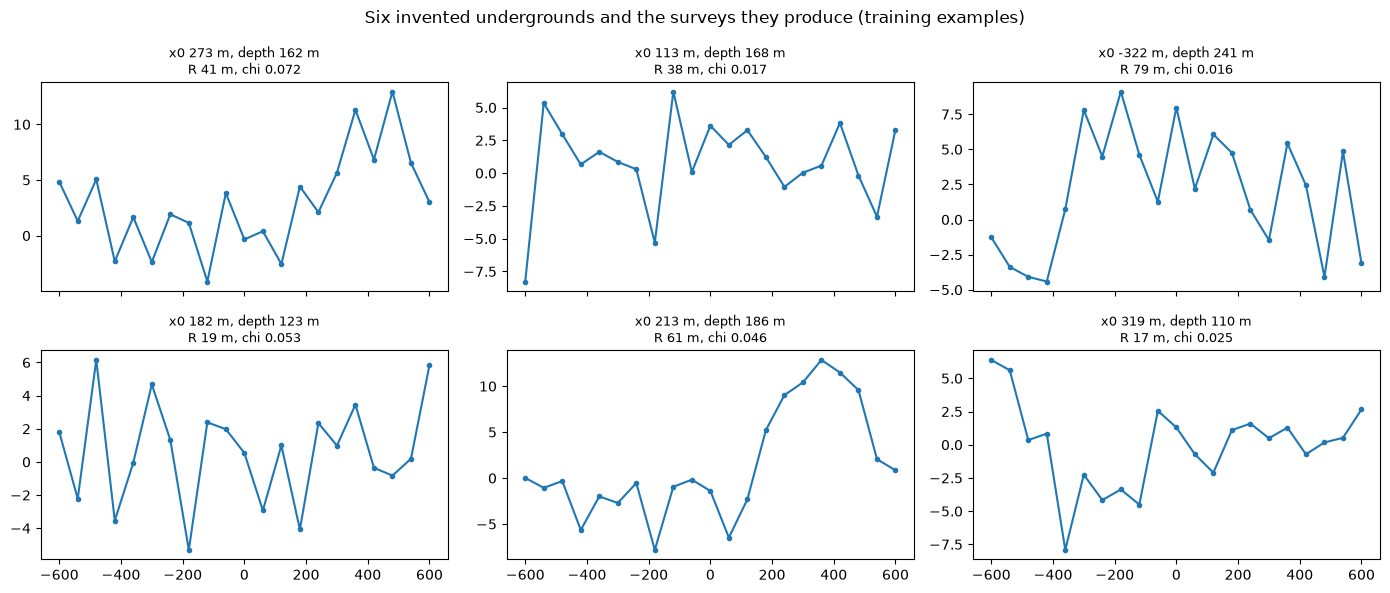

conditional flow: 484,512 trainable numbers


In [2]:
gen = torch.Generator().manual_seed(123)
theta_ex, readings_ex = gm.simulate(6, x_sensors, NOISE, generator=gen)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for a, th, r in zip(axes.flat, theta_ex, readings_ex):
    p = gm.theta_to_phys(th[None])
    a.plot(x_sensors, r, "o-", ms=3)
    a.set_title(f"x0 {p['x0'].item():.0f} m, depth {p['depth'].item():.0f} m\nR {p['radius'].item():.0f} m, chi {p['chi'].item():.3f}", fontsize=9)
fig.suptitle("Six invented undergrounds and the surveys they produce (training examples)"); plt.tight_layout(); plt.show()

cflow = gm.make_spline_flow(4, n_layers=6, hidden=128, context_dim=N_CTX)
print(f"conditional flow: {sum(p.numel() for p in cflow.parameters()):,} trainable numbers")

## 2. Train: Recipe A on an endless stream of simulations

Every step uses **brand-new** simulated surveys, so the flow can't memorise — there's no fixed training set.
Loss = `−log q(true underground | readings)`: "make the underground that really produced these readings as likely as possible."

loaded trained flow from models\lesson03_cflow.pt (originally trained in 9.4 min)


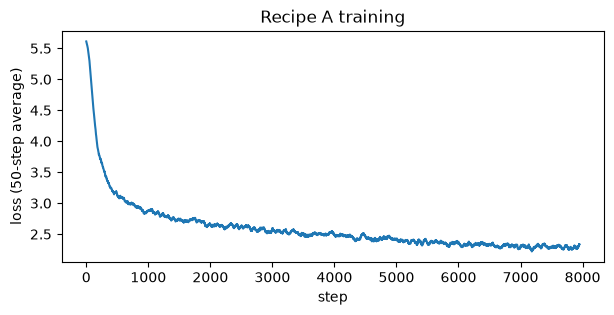

In [3]:
# Training takes ~10 minutes, so the result is saved; set RETRAIN = True to train from scratch again.
RETRAIN = False
MODEL_PATH = Path("models/lesson03_cflow.pt")
N_ITER, BATCH = 8000, 512

if MODEL_PATH.exists() and not RETRAIN:
    saved = torch.load(MODEL_PATH)
    cflow.load_state_dict(saved["state"]); losses, train_time = saved["losses"], saved["train_time"]
    cflow.eval()
    print(f"loaded trained flow from {MODEL_PATH} (originally trained in {train_time/60:.1f} min)")
else:
    opt = torch.optim.Adam(cflow.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=N_ITER, pct_start=0.05)
    losses = []
    t0 = time.time()
    for it in range(N_ITER):
        theta_b, readings_b = gm.simulate(BATCH, x_sensors, NOISE)
        loss = cflow.forward_kld(theta_b, context=gm.readings_to_context(readings_b, NOISE))
        opt.zero_grad()
        if torch.isfinite(loss):
            loss.backward()
            torch.nn.utils.clip_grad_norm_(cflow.parameters(), 10.0)
            opt.step()
        sched.step()
        losses.append(loss.item())
        if (it + 1) % 1000 == 0:
            print(f"step {it+1:5d}  loss {np.mean(losses[-200:]):.3f}   ({time.time()-t0:.0f}s)")
    cflow.eval()
    train_time = time.time() - t0
    MODEL_PATH.parent.mkdir(exist_ok=True)
    torch.save({"state": cflow.state_dict(), "losses": losses, "train_time": train_time}, MODEL_PATH)

plt.figure(figsize=(7, 3)); plt.plot(np.convolve(losses, np.ones(50) / 50, mode="valid"))
plt.xlabel("step"); plt.ylabel("loss (50-step average)"); plt.title("Recipe A training"); plt.show()

**How low can the loss go?** At the start the flow ignores the readings, so the loss is about the prior's entropy (5.68 for 4 standard normals).
Every bit it drops below that is information it has learned to extract from the readings.

## 3. Test on Lesson 2's survey
Same hidden lump, same noise seed as Lesson 2, so we can compare with MCMC on exactly the same readings.

In [4]:
def sample_given(readings, n=20000):
    """Pictures of the underground for one survey: repeat its recipe card n times."""
    ctx = gm.readings_to_context(readings, NOISE).reshape(1, -1).expand(n, -1)
    with torch.no_grad():
        return cflow.sample(n, context=ctx)

TRUE = dict(x0=40.0, depth=200.0, radius=40.0, chi=0.12)
theta_true = gm.phys_to_theta(**TRUE)
clean = gm.predict(theta_true, x_sensors)[0]
readings = clean + NOISE * torch.randn(len(x_sensors), generator=torch.Generator().manual_seed(1))

t0 = time.time()
theta_c, log_q_c = sample_given(readings)
t_amortized = time.time() - t0

posterior = gm.SpherePosterior(x_sensors, readings, NOISE)
t0 = time.time()
mcmc, acc, rhat = gm.run_mcmc(posterior.log_prob, gm.find_map(posterior.log_prob, 4))
t_mcmc = time.time() - t0
print(f"conditional flow: 20,000 pictures in {t_amortized*1000:.0f} ms  (after {train_time/60:.1f} min of one-off training)")
print(f"MCMC for this one survey: {t_mcmc:.1f} s   (Lesson 2's Recipe B flow: ~2.5 min of training per survey)")

conditional flow: 20,000 pictures in 349 ms  (after 9.4 min of one-off training)
MCMC for this one survey: 4.4 s   (Lesson 2's Recipe B flow: ~2.5 min of training per survey)


In [5]:
P_c, P_m = gm.phys_matrix(theta_c).numpy(), gm.phys_matrix(mcmc).numpy()
P_true = gm.phys_matrix(theta_true).numpy()[0]
qs = torch.tensor([0.05, 0.5, 0.95])
gaps = []
print(f"{'':22s}{'5%':>22s}{'median':>22s}{'95%':>22s}     truth")
for i, name in enumerate(gm.PARAM_NAMES):
    qc = np.quantile(P_c[:, i], qs.numpy()); qm = np.quantile(P_m[:, i], qs.numpy())
    print(f"{name:22s}" + "".join(f"{c:>10.3g} / {m:<9.3g}" for c, m in zip(qc, qm)) + f"  {P_true[i]:8.3g}")
    gaps.append(((torch.quantile(theta_c[:, i], qs) - torch.quantile(mcmc[:, i], qs)).abs().max() / mcmc[:, i].std()).item())
print("(each cell: conditional flow / MCMC)")
print("worst quantile gap per parameter, in MCMC-std units:", [round(g, 3) for g in gaps])

with torch.no_grad():
    ess_c = gm.importance_ess(posterior.log_prob(theta_c), log_q_c)
print(f"importance ESS against the exact posterior: {ess_c:.1%}   (Lesson 2's single-survey flow: ~98%)")

                                          5%                median                   95%     truth
x0 (m)                     -9.41 / -10.7          18.5 / 16.4           45.9 / 42.3             40
depth (m)                    148 / 165             198 / 211             255 / 265             200
radius (m)                  29.8 / 31.5           48.3 / 50.2           78.7 / 80.6             40
susceptibility (SI)       0.0238 / 0.0253       0.0974 / 0.1           0.385 / 0.394          0.12
(each cell: conditional flow / MCMC)
worst quantile gap per parameter, in MCMC-std units: [0.225, 0.728, 0.187, 0.073]
importance ESS against the exact posterior: 77.0%   (Lesson 2's single-survey flow: ~98%)


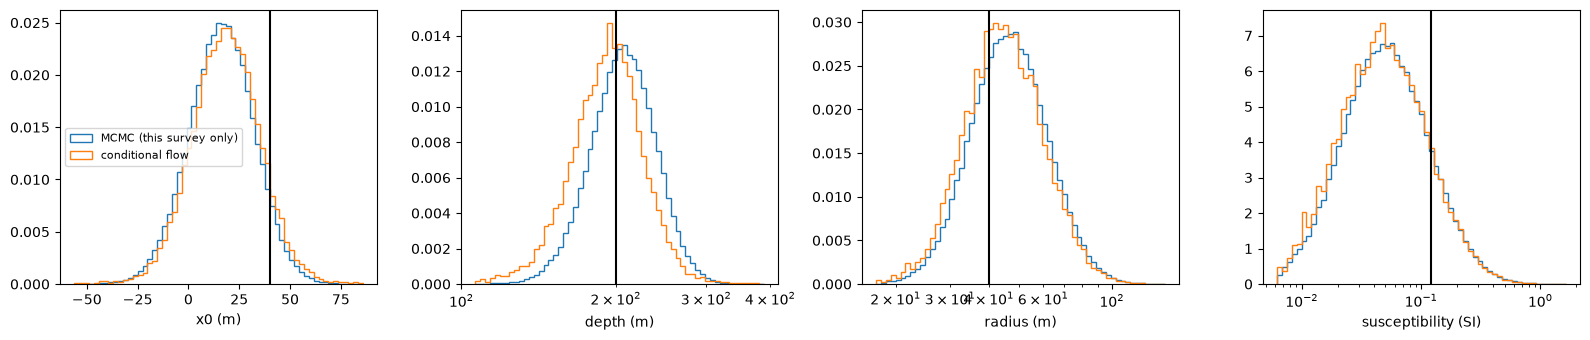

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for i, a in enumerate(axes):
    log = i > 0
    lo, hi = np.quantile(P_m[:, i], [0.001, 0.999])
    bins = np.geomspace(lo / 1.2, hi * 1.2, 60) if log else np.linspace(lo - 20, hi + 20, 60)
    a.hist(P_m[:, i], bins=bins, density=True, histtype="step", label="MCMC (this survey only)")
    a.hist(P_c[:, i], bins=bins, density=True, histtype="step", label="conditional flow")
    a.axvline(P_true[i], color="k"); a.set_xlabel(gm.PARAM_NAMES[i])
    if log: a.set_xscale("log")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

The "one-size-fits-all" flow is close but noticeably less accurate than the made-to-measure answer (look at depth) — that's the **amortization gap**.
Its training loss was also still falling, so some of the gap is just "could have trained longer".

### Closing the gap: fine-tune on this one survey
A published fix (Siahkoohi et al. 2023, for seismic imaging): start from the conditional flow, freeze its recipe card to *this* survey,
and run a few hundred steps of **Recipe B** (the physics score from Lesson 2). We keep the original intact by working on a copy.

fine-tuning took 24s
worst quantile gap per parameter (MCMC-std units):  before [0.23, 0.73, 0.19, 0.07]   after [0.02, 0.08, 0.12, 0.13]
importance ESS: before 77.0%   after 87.1%


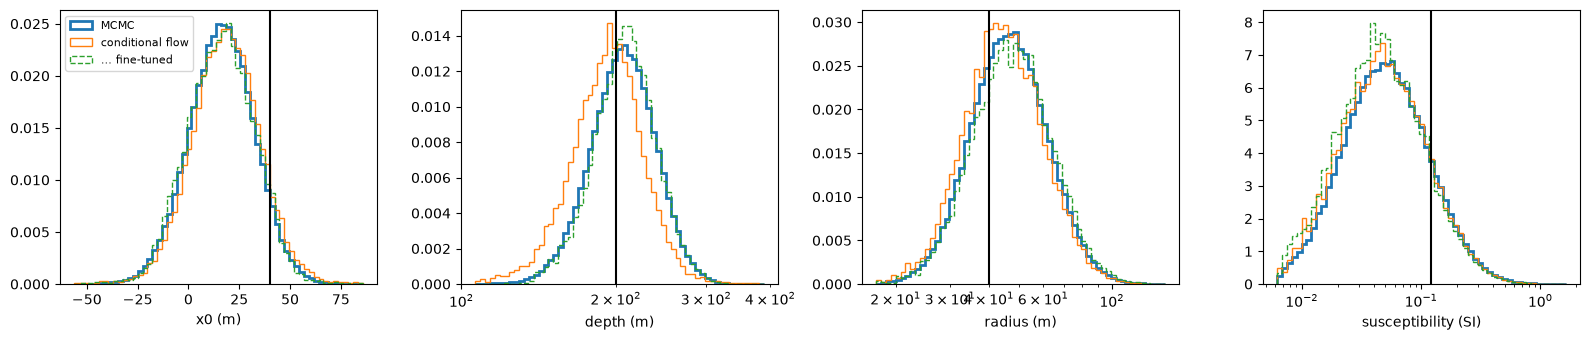

In [7]:
import copy

def fine_tune(base_flow, readings, n_iter=400, n_samples=256, lr=1e-4):
    ft = copy.deepcopy(base_flow); ft.train()
    post = gm.SpherePosterior(x_sensors, readings, NOISE)
    ctx = gm.readings_to_context(readings, NOISE).reshape(1, -1).expand(n_samples, -1)
    opt = torch.optim.Adam(ft.parameters(), lr=lr)
    for it in range(n_iter):
        theta, log_q = ft.sample(n_samples, context=ctx)      # dice -> pictures, with exact log q
        loss = (log_q - post.log_prob(theta)).mean()          # Recipe B: "score high, don't crowd"
        opt.zero_grad()
        if torch.isfinite(loss):
            loss.backward(); torch.nn.utils.clip_grad_norm_(ft.parameters(), 10.0); opt.step()
    ft.eval()
    return ft

t0 = time.time()
cflow_ft = fine_tune(cflow, readings)
t_ft = time.time() - t0
ctx = gm.readings_to_context(readings, NOISE).reshape(1, -1).expand(20000, -1)
with torch.no_grad():
    theta_ft, log_q_ft = cflow_ft.sample(20000, context=ctx)
    ess_ft = gm.importance_ess(posterior.log_prob(theta_ft), log_q_ft)
gaps_ft = [((torch.quantile(theta_ft[:, i], qs) - torch.quantile(mcmc[:, i], qs)).abs().max() / mcmc[:, i].std()).item() for i in range(4)]
print(f"fine-tuning took {t_ft:.0f}s")
print("worst quantile gap per parameter (MCMC-std units):  before", [round(g, 2) for g in gaps], "  after", [round(g, 2) for g in gaps_ft])
print(f"importance ESS: before {ess_c:.1%}   after {ess_ft:.1%}")

P_ft = gm.phys_matrix(theta_ft).numpy()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for i, a in enumerate(axes):
    log = i > 0
    lo, hi = np.quantile(P_m[:, i], [0.001, 0.999])
    bins = np.geomspace(lo / 1.2, hi * 1.2, 60) if log else np.linspace(lo - 20, hi + 20, 60)
    a.hist(P_m[:, i], bins=bins, density=True, histtype="step", lw=2, label="MCMC")
    a.hist(P_c[:, i], bins=bins, density=True, histtype="step", label="conditional flow")
    a.hist(P_ft[:, i], bins=bins, density=True, histtype="step", ls="--", label="… fine-tuned")
    a.axvline(P_true[i], color="k"); a.set_xlabel(gm.PARAM_NAMES[i])
    if log: a.set_xscale("log")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

Workflow in practice: the conditional flow gives an **instant first answer** for every survey; for the few surveys you'll actually spend money on,
fine-tune (seconds) and check the importance ESS.

## 4. Coverage test: are the 90% ranges honest?

For 500 brand-new simulated surveys (truth known), ask for pictures and check where the truth falls.
For every confidence level (10%, 20%, …, 90%), count how often the truth landed inside that central range.
**Honest = on the diagonal.** Below the diagonal = overconfident (dangerous). Above = too cautious (safe but blurry).

500 coverage tests in 23s


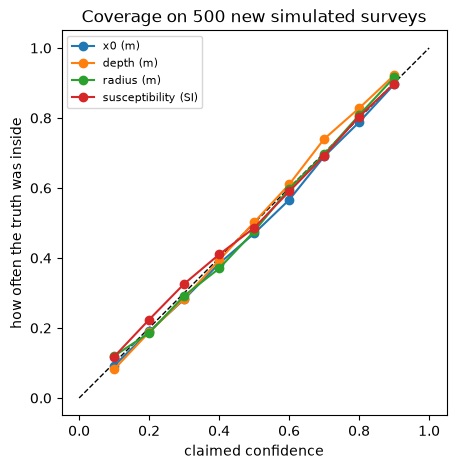

x0 (m)                 90% ranges contained the truth 89.6% of the time
depth (m)              90% ranges contained the truth 92.2% of the time
radius (m)             90% ranges contained the truth 91.6% of the time
susceptibility (SI)    90% ranges contained the truth 89.8% of the time


In [8]:
def coverage(theta_true_batch, readings_batch, n=2000, levels=np.linspace(0.1, 0.9, 9)):
    """For each test survey: fraction of flow samples below the truth (per parameter) -> coverage at each level."""
    ranks = []
    for th, r in zip(theta_true_batch, readings_batch):
        s, _ = sample_given(r, n)
        ranks.append((s < th).double().mean(0))
    ranks = torch.stack(ranks).numpy()                      # (n_tests, 4), each in [0, 1]
    cov = np.array([[np.mean(np.abs(ranks[:, i] - 0.5) <= lv / 2) for lv in levels] for i in range(4)])
    return levels, cov, ranks

t0 = time.time()
theta_test, readings_test = gm.simulate(500, x_sensors, NOISE, generator=torch.Generator().manual_seed(7))
levels, cov_ok, ranks_ok = coverage(theta_test, readings_test)
print(f"500 coverage tests in {time.time()-t0:.0f}s")

def plot_coverage(levels, cov, title):
    plt.figure(figsize=(5, 5))
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    for i, name in enumerate(gm.PARAM_NAMES):
        plt.plot(levels, cov[i], "o-", label=name)
    plt.xlabel("claimed confidence"); plt.ylabel("how often the truth was inside")
    plt.title(title); plt.legend(fontsize=8); plt.gca().set_aspect("equal"); plt.show()

plot_coverage(levels, cov_ok, "Coverage on 500 new simulated surveys")
for i, name in enumerate(gm.PARAM_NAMES):
    print(f"{name:22s} 90% ranges contained the truth {cov_ok[i, -1]:.1%} of the time")

With 500 tests, ±3% wiggle around the diagonal is just luck. (This is the coverage / simulation-based-calibration test from Talts et al. 2018.)

## 5. Break the simulator

Real ironstones often come in clusters. Suppose the real ground has a **second lump** near the first —
something our simulator never produced. We ask the same flow about such surveys and re-run the coverage test (for the *main* lump).

How much this hurts depends on how big the unmodelled thing is, so we try two versions:
- **weak:** second lump 250–400 m away with about half the magnet strength
- **strong:** second lump 150–300 m away with the same magnet strength

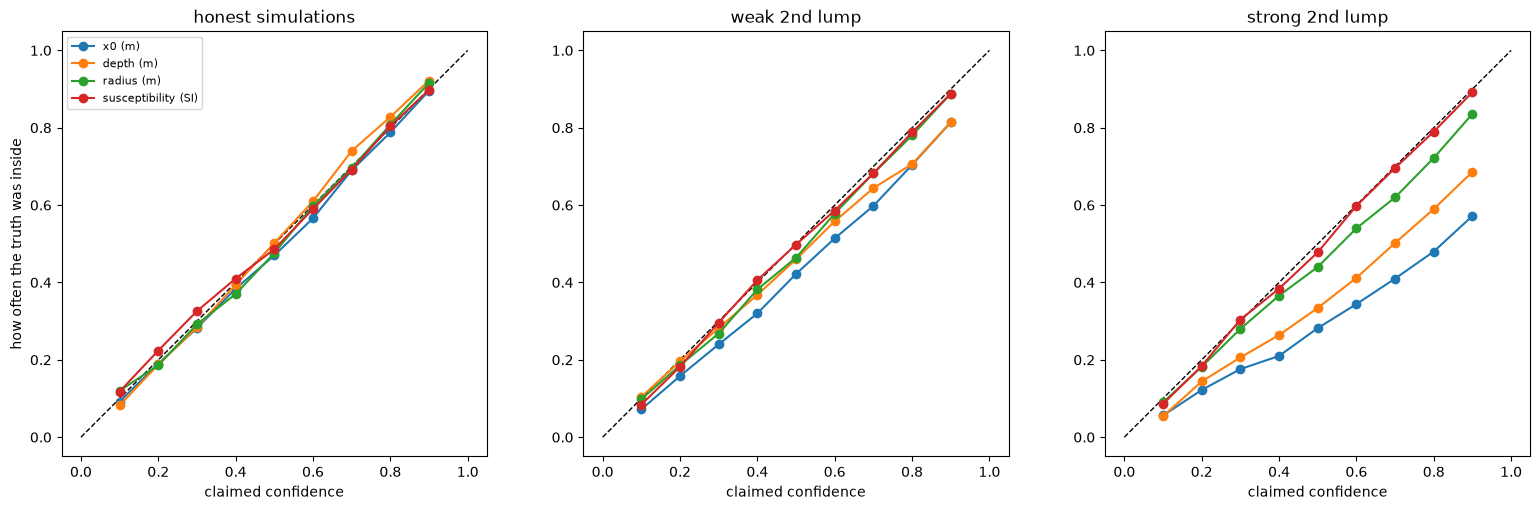

90% ranges contained the truth:       honest     weak 2nd lump   strong 2nd lump
x0 (m)                                 89.6%             81.4%             57.2%
depth (m)                              92.2%             81.4%             68.6%
radius (m)                             91.6%             88.8%             83.6%
susceptibility (SI)                    89.8%             88.8%             89.2%


In [9]:
def simulate_two_lumps(n, generator, strength_ratio, dist_range):
    theta_main, _ = gm.simulate(n, x_sensors, NOISE, generator=generator)
    p = gm.theta_to_phys(theta_main)
    side = torch.where(torch.rand(n, generator=generator) < 0.5, -1.0, 1.0)
    x2 = p["x0"] + side * (dist_range[0] + (dist_range[1] - dist_range[0]) * torch.rand(n, generator=generator))
    d2 = p["depth"] * (0.8 + 0.4 * torch.rand(n, generator=generator))
    r2 = p["radius"] * strength_ratio ** (1 / 3)        # strength scales with radius^3
    clean = gm.predict(theta_main, x_sensors) + gm.sphere_tmi(x_sensors, x2, d2, r2, p["chi"])
    return theta_main, clean + NOISE * torch.randn(clean.shape, generator=generator)

scenarios = {
    "weak 2nd lump": dict(strength_ratio=0.5, dist_range=(250, 400)),
    "strong 2nd lump": dict(strength_ratio=1.0, dist_range=(150, 300)),
}
broken = {}
for k, (name, kw) in enumerate(scenarios.items()):
    th, rd = simulate_two_lumps(500, torch.Generator().manual_seed(8 + k), **kw)
    _, cov, ranks = coverage(th, rd)
    broken[name] = dict(theta=th, readings=rd, cov=cov, ranks=ranks)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for a, (title, cov) in zip(axes, [("honest simulations", cov_ok)] + [(n, b["cov"]) for n, b in broken.items()]):
    a.plot([0, 1], [0, 1], "k--", lw=1)
    for i, name in enumerate(gm.PARAM_NAMES):
        a.plot(levels, cov[i], "o-", label=name)
    a.set_title(title); a.set_xlabel("claimed confidence"); a.set_aspect("equal")
axes[0].set_ylabel("how often the truth was inside"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'90% ranges contained the truth:':34s}{'honest':>10s}" + "".join(f"{n:>18s}" for n in broken))
for i, name in enumerate(gm.PARAM_NAMES):
    print(f"{name:34s}{cov_ok[i, -1]:>10.1%}" + "".join(f"{b['cov'][i, -1]:>18.1%}" for b in broken.values()))

The flow never complains — it can't. It was never shown a two-lump survey, so it confidently explains everything with one lump.
A small unmodelled lump costs a little honesty; a big one makes "90% sure" mean much less. This is the "practice vs. real game" gap.

### Catching it without knowing the truth
Same idea as Lesson 2: take the best picture, predict the readings, and measure the leftovers in noise units.
Set the alarm so it fires on only 5% of normal surveys, and see how often it fires on the broken ones.

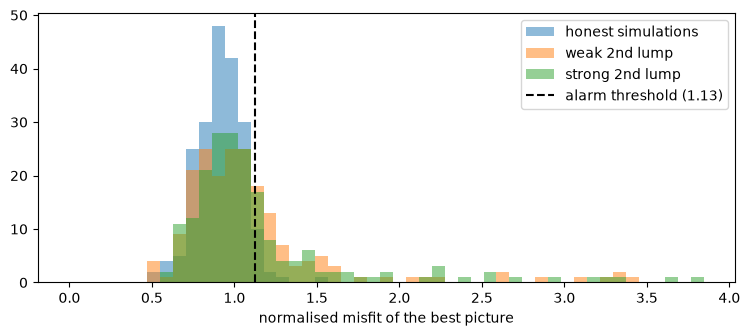

weak 2nd lump   : alarm fired on 31% of surveys.  x0 90%-coverage — surveys that passed the alarm: 82%,  surveys that raised it: 77%
strong 2nd lump : alarm fired on 34% of surveys.  x0 90%-coverage — surveys that passed the alarm: 71%,  surveys that raised it: 36%


In [10]:
def misfit_of(readings, n=2000):
    s, _ = sample_given(readings, n)
    post = gm.SpherePosterior(x_sensors, readings, NOISE)
    with torch.no_grad():
        best = s[post.log_prob(s).argmax()][None]
        resid = readings - gm.predict(best, x_sensors)[0]
    return (resid / NOISE).pow(2).mean().sqrt().item()

N_ALARM = 200
mis_ok = np.array([misfit_of(r) for r in readings_test[:N_ALARM]])
threshold = np.quantile(mis_ok, 0.95)
for b in broken.values():
    b["misfit"] = np.array([misfit_of(r) for r in b["readings"][:N_ALARM]])
    b["flagged"] = np.mean(b["misfit"] > threshold)

bins = np.linspace(0, np.quantile(broken["strong 2nd lump"]["misfit"], 0.95), 50)
plt.figure(figsize=(9, 3.5))
plt.hist(mis_ok, bins=bins, alpha=0.5, label="honest simulations")
for n, b in broken.items():
    plt.hist(b["misfit"], bins=bins, alpha=0.5, label=n)
plt.axvline(threshold, color="k", ls="--", label=f"alarm threshold ({threshold:.2f})")
plt.xlabel("normalised misfit of the best picture"); plt.legend(); plt.show()

for n, b in broken.items():
    inside = np.abs(b["ranks"][:N_ALARM, 0] - 0.5) <= 0.45
    passed = b["misfit"] <= threshold
    print(f"{n:16s}: alarm fired on {b['flagged']:.0%} of surveys.  x0 90%-coverage — surveys that passed the alarm: {inside[passed].mean():.0%},  "
          f"surveys that raised it: {inside[~passed].mean() if (~passed).any() else float('nan'):.0%}")

The alarm is a **weak safety net**: even with a strong second lump it stays silent on most surveys.
Surveys that *do* raise it are the ones where the flow is most wrong, but plenty of wrong answers slip through quietly.

Why so many misses? Many surveys in our prior have a faint main signal (a deep or weakly magnetic lump). A second lump hiding under 3 nT noise
simply can't be seen in the readings — no check on the readings could catch it. Let's split by how strong the signal is:

In [11]:
for n, b in broken.items():
    peak_snr = (gm.predict(b["theta"][:N_ALARM], x_sensors).abs().max(1).values / NOISE).numpy()
    strong_sig = peak_snr > 5
    print(f"{n:16s}: alarm rate when main signal > 5x noise: {np.mean(b['misfit'][strong_sig] > threshold):.0%} (of {strong_sig.sum()} surveys);  "
          f"when fainter: {np.mean(b['misfit'][~strong_sig] > threshold):.0%} (of {(~strong_sig).sum()})")

weak 2nd lump   : alarm rate when main signal > 5x noise: 82% (of 39 surveys);  when fainter: 19% (of 161)
strong 2nd lump : alarm rate when main signal > 5x noise: 91% (of 44 surveys);  when fainter: 17% (of 156)


Lesson for real data: a passing misfit check does **not** prove the physics is right — it only fails to prove it wrong.
A failing check is a strong signal: "don't trust the pictures yet — fix the physics". Independent evidence (geology, drill holes) is still needed.

## Report card

In [12]:
strong, weak = broken["strong 2nd lump"], broken["weak 2nd lump"]
results = {
    "conditional flow: importance ESS > 20% on Lesson 2's survey": ess_c > 0.20,
    "fine-tuning closes the gap: all quantile gaps < 0.25 MCMC-std": max(gaps_ft) < 0.25,
    "fine-tuning raises importance ESS": ess_ft > ess_c,
    "honest coverage: all 90% ranges contain truth 85-95% of the time": bool(np.all((cov_ok[:, -1] > 0.85) & (cov_ok[:, -1] < 0.95))),
    "honest coverage: every level within 6% of the diagonal": bool(np.all(np.abs(cov_ok - levels) < 0.06)),
    "unmodelled lump hurts more when bigger (x0 coverage: honest > weak > strong)": cov_ok[0, -1] > weak["cov"][0, -1] > strong["cov"][0, -1],
    "strong 2nd lump: x0 90% coverage below 75%": strong["cov"][0, -1] < 0.75,
    "misfit alarm fires more for the strong lump than the weak one": strong["flagged"] > weak["flagged"],
    "misfit alarm fires on strong-lump surveys well above its 5% false-alarm rate (> 15%)": strong["flagged"] > 0.15,
}
for k, v in results.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(results.values()), "some checks failed"

PASS  conditional flow: importance ESS > 20% on Lesson 2's survey
PASS  fine-tuning closes the gap: all quantile gaps < 0.25 MCMC-std
PASS  fine-tuning raises importance ESS
PASS  honest coverage: all 90% ranges contain truth 85-95% of the time
PASS  honest coverage: every level within 6% of the diagonal
PASS  unmodelled lump hurts more when bigger (x0 coverage: honest > weak > strong)
PASS  strong 2nd lump: x0 90% coverage below 75%
PASS  misfit alarm fires more for the strong lump than the weak one
PASS  misfit alarm fires on strong-lump surveys well above its 5% false-alarm rate (> 15%)


## Take-aways
- Train once (minutes), then answer any survey **in milliseconds**. Useful when screening many lines or areas.
- The price is an **amortization gap**; fine-tuning on the one survey you care about closes most of it in seconds.
- Because answers are instant, we can afford the **coverage test** — the best way to know whether "90% sure" means 90%.
- A conditional flow is only as good as its simulator. When reality has something the simulator never made, it becomes **confidently wrong without warning** —
  A physics-based misfit check helps, but it's a partial net: passing it doesn't prove the physics is right.

**Next lesson:** real airborne magnetic data from the Osborne copper-gold mine.